# Steam Dataset Data Mining Exercise

This notebook applies a full data mining suite of techniques to a dataset of Steam released games in order to investigate one core question: *Does releasing more games make a developer more succesful?*

We will go though the full flow of practices, from loading and inspecting our data, to transforming it and applying data mining algorithms, in the aim to arrive to meaningful observations and conclusions


## Step 0 - Importing and loading the data

In [130]:
# Necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from datetime import datetime
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import (
apriori, association_rules)

from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

NOTE: Because `Discount` and `DLC count` are not properly comma separated in `games,csv`, we need to explicitely pass the columns to be read

In [131]:
columns = ['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'Discount', 'DLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']

df = pd.read_csv("games.csv",names=columns, header=0)

## Step 1 - Data Understanding and Quality

Let's take a look at our dataset

In [132]:
df.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


In [133]:
df.shape

(125855, 40)

In [134]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  str    
 2   Release date                125855 non-null  str    
 3   Estimated owners            125855 non-null  str    
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  str    
 10  Supported languages         125855 non-null  str    
 11  Full audio languages        125855 non-null  str    
 12  Reviews                     12181 non-null   str    
 13  Header image             

In [135]:
df.dtypes

AppID                           int64
Name                              str
Release date                      str
Estimated owners                  str
Peak CCU                        int64
Required age                    int64
Price                         float64
Discount                        int64
DLC count                       int64
About the game                    str
Supported languages               str
Full audio languages              str
Reviews                           str
Header image                      str
Website                           str
Support url                       str
Support email                     str
Windows                          bool
Mac                              bool
Linux                            bool
Metacritic score                int64
Metacritic url                    str
User score                      int64
Positive                        int64
Negative                        int64
Score rank                    float64
Achievements

In [136]:
df.columns

Index(['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU',
       'Required age', 'Price', 'Discount', 'DLC count', 'About the game',
       'Supported languages', 'Full audio languages', 'Reviews',
       'Header image', 'Website', 'Support url', 'Support email', 'Windows',
       'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score',
       'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations',
       'Notes', 'Average playtime forever', 'Average playtime two weeks',
       'Median playtime forever', 'Median playtime two weeks', 'Developers',
       'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies'],
      dtype='str')

We have a dataframe of steam games, with 125855 entries, s.t our data object represents a distinct game available on the Steam store, and 40 attributes, describing each entry, such as its name, price, and more.
For detailed information on all attributes, see `data_dictionary.md`

In [137]:
# not every attribute is meaningful to get statistics on, such as App ID
numerical_features_of_interest = ['Peak CCU', 'Required age', 'Price', 'Discount', 'DLC count', 'Metacritic score', 'User score', 'Positive', 'Negative', 'Score rank', 'Recommendations', 'Average playtime forever','Average playtime two weeks', 'Median playtime forever','Median playtime two weeks']
df[numerical_features_of_interest].describe()

,Peak CCU,Required age,Price,Discount,DLC count,Metacritic score,User score,Positive,Negative,Score rank,Recommendations,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks
count,1.258550e+05,125855.000000,125855.000000,125855.000000,125855.000000,125855.000000,125855.000000,1.258550e+05,1.258550e+05,40.000000,1.258550e+05,1.258550e+05,125855.000000,1.258550e+05,125855.000000
mean,5.318720e+01,0.165365,4.811174,17.896826,0.535434,2.500083,0.023916,1.018182e+03,1.648786e+02,99.175000,9.380399e+02,2.027568e+02,13.507711,1.691803e+02,14.419125
std,3.681083e+03,1.642666,12.489329,28.628518,14.328417,13.492922,1.376811,2.772782e+04,5.305001e+03,0.675107,2.159585e+04,1.107222e+04,266.925759,1.105725e+04,290.747134
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,98.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,0.000000e+00,0.000000,0.590000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,99.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
50%,0.000000e+00,0.000000,2.390000,0.000000,0.000000,0.000000,0.000000,4.000000e+00,1.000000e+00,99.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
75%,0.000000e+00,0.000000,5.545000,37.000000,0.000000,0.000000,0.000000,3.500000e+01,1.000000e+01,100.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
max,1.013936e+06,21.000000,999.980000,100.000000,3703.000000,97.000000,100.000000,7.642084e+06,1.173003e+06,100.000000,4.830455e+06,3.429544e+06,20088.000000,3.429544e+06,20088.000000


Let us do a small quality check for the initial data

In [138]:
df.isna().sum()

AppID                              0
Name                               1
Release date                       0
Estimated owners                   0
Peak CCU                           0
Required age                       0
Price                              0
Discount                           0
DLC count                          0
About the game                  8462
Supported languages                0
Full audio languages               0
Reviews                       113674
Header image                      81
Website                        75335
Support url                    70560
Support email                  22630
Windows                            0
Mac                                0
Linux                              0
Metacritic score                   0
Metacritic url                121597
User score                         0
Positive                           0
Negative                           0
Score rank                    125815
Achievements                       0
R

In [139]:
df.isnull().sum()

AppID                              0
Name                               1
Release date                       0
Estimated owners                   0
Peak CCU                           0
Required age                       0
Price                              0
Discount                           0
DLC count                          0
About the game                  8462
Supported languages                0
Full audio languages               0
Reviews                       113674
Header image                      81
Website                        75335
Support url                    70560
Support email                  22630
Windows                            0
Mac                                0
Linux                              0
Metacritic score                   0
Metacritic url                121597
User score                         0
Positive                           0
Negative                           0
Score rank                    125815
Achievements                       0
R

In [140]:
df.duplicated().sum()

np.int64(0)

We can see it is not perfeclty clean initially, but we won't immediatly act on it, as we will filter out a lot of it to create a new dataframe of interest

### Data aggregation
For our analysis, we need a dataframe of developers, not of games. For this, we will group all games that share a developer, and look at the count of games released, overall engagement, and average price for each developer.

First, we need to transform the original dataframe, by fixing the format of the `Release data` column and adding an `Effort` metric to each game. This will help us further down for the aggregation

In [141]:
df['Release date'] = pd.to_datetime(df['Release date']) # converting the release date to a pandas datetime object
df['Effort'] = (
    df['Screenshots'].fillna('').str.count(',') + 
    df['Screenshots'].notna().astype(int) +
    df['About the game'].fillna('').str.len() / 500
) # addding an effort metric to each game based on screenshot counts and description text lengths

NOTE: `pd.to_datetime` converts NaN and Null values to NaT (Not a Time) objects; further down, pandas agreggation will simply skip any enties with NaT, but if a developer has all missing dates, then that attribute will have NaT. Additionally, any NaN entries for either `Screenshots` or `About the game` get replaced with empty strings, allowing for no errors in the calculation of `Effort`

There are a couple fo data transformations steps we need to take, as there are attributes that we wish to add, and counts we need to update

Here, we will add every game a weight of 1, but if it has any DLCs associated with it, that weight gets increased to 2, so when we count games by develoepers, we will consider DLCs as 1 extra game. This is a compromise between not taking DLCs into consideration at all, and counting every single DLC as an individual game, since certain DLC's take great effort to be developed, whereas others are merely cosmetics. We had noticed certain games had few high effort DLCs, whereas others had hundreds, but each being merely a downloadable skin or cosmetic.

In [142]:
df['game_weight'] = 1 # every entry defaults to 1

df.loc[df['DLC count'] >=1, 'game_weight'] = 2 # if a game has DLC count >= 1, increase that weight to 2

In [143]:
# Aggregate genres across all games by developer
def aggregate_genres(genres):
    unique_genres = set()
    for game_genres in genres.dropna():
        for genre in game_genres.split(','):
            unique_genres.add(genre.strip())
    return ','.join(sorted(unique_genres))
def aggregate_genres_count(genres):
    unique_genres = set()
    for game_genres in genres.dropna():
        for genre in game_genres.split(','):
            unique_genres.add(genre.strip())
    return len(unique_genres)

In [144]:
# Group by developer and aggregate features
developers_df = df.groupby('Developers').agg(
    game_count=('game_weight', 'sum'), # how many games released, taking DLC into consideration
    total_positive=('Positive', 'sum'), # total positive reviews
    total_negative=('Negative', 'sum'), # total negative reviews
    avg_price=('Price', 'mean'), # average game price
    max_success=('Positive', 'max'), # highest success in developers career
    genres=('Genres', aggregate_genres), # all the genres a developer has used
    genre_count=('Genres', aggregate_genres_count), # count of genres per developer
    start_year=('Release date', 'min'), # year of first game released
    end_year=('Release date', 'max'), # year of last game released
    avg_effort=('Effort', 'mean') # average effort put into steam pages for games
).reset_index()

NOTE: pandas `groupby()` handles missing entries by itself!
- Any entries in `Developers` with a missing value get skipped
- If a specific cell in a collum being aggregated is missing, pandas functions (sum, mean, max, min) will ignore the missing cell for the calculation
    - Ex: if a developer has 3 games, but one has `Price` as NaN, `avg_price` will only use the 2 valid values, and divide by 2, instead of simply having `avg_price` = NaN

Adding 2 more metrics, `engagement` and `avg_game_success`

In [145]:
developers_df['engagement'] = developers_df['total_positive'] + developers_df['total_negative'] # engagement attribute: sum of total "interactions" with the game, be it positive or negative votes
developers_df['avg_game_success'] =developers_df['engagement'] / developers_df['game_count'] # avg_game_success attribute: the average engagement of a developer across all their games released

Adding two final features, `years_active` and `frequency`

In [146]:
# helper function to extract how many years a developer worked, by subtracting the date of their last release with the first one
def get_years_active(dataframe, end_year_column, start_year_column):
    years_active_list = []
    for row in dataframe.itertuples(index=True):
        index = row[0]
        start_value = start_year_column[index].year
        end_value = end_year_column[index].year
        difference = int(end_value) - int(start_value) + 1
        years_active_list.append(difference)
    dataframe['years_active'] = years_active_list # adding the new attribute into our dataframe

In [147]:
get_years_active(developers_df, developers_df['end_year'], developers_df['start_year']) # calling our helper function to extract the active years fo a developer
developers_df['frequency'] = developers_df['game_count'] / developers_df['years_active'] # frequency attribute: ratio of games released over the active years of a developer

The new dataframe will look as follows, with the new data object being an individual developer, with attributes pertaining their career

In [148]:
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0


The data dictionary for this new dataframe is:

| Attribute | Statistical Data Type | What it describes |
| :--- | :--- | :--- |
| **Developers** | Categorical | Unique name of the game developer  |
| **game_count** | Ratio | Total weighted count of games released by the developer, where games with $\ge 1$ DLC are counted with an increased weight of 2. |
| **total_positive** | Ratio | Cumulative sum of positive user reviews received across all games from the developer |
| **total_negative** | Ratio | Cumulative sum of negative user reviews received across all games from the developer |
| **avg_price** | Continuous | Mean base price (in USD) across all games released by the developer on the Steam store |
| **max_success** | Ratio | Highest number of positive reviews achieved by a single game within the developer's career (peak career success) |
| **genres** | Categorical | Alphabetically sorted, comma-separated string aggregating all unique genres utilized across all the games of a developer |
| **genre_count** | Ratio | Count of distinct genres a developer has worked across in their career |
| **start_year** | Ordinal / Temporal | Year when the developer released their first recorded game. |
| **end_year** | Ordinal / Temporal | Year of the developer's most recent game release |
| **avg_effort** | Continuous | Mean metric quantifying the design effort put into the developer's Steam store pages, calculated based on screenshot counts and description text lengths |
| **engagement** | Ratio | Sum of `positive` and `negative` to gauge total engagement a game received |
| **avg_game_success** | Continuous | Mean `engagement` raised across all games under a single developer |
| **years_active** | Ratio | Count of the tears in activity of a developer, counted as `end_year` - `start_year` |
| **frequency** | Ratio | Ratio of how many games a developer releases per year, derived from `game_count`/`years_active` |

### Data Quality - revisited

In [149]:
developers_df.isna().sum()

Developers          0
game_count          0
total_positive      0
total_negative      0
avg_price           0
max_success         0
genres              0
genre_count         0
start_year          0
end_year            0
avg_effort          0
engagement          0
avg_game_success    0
years_active        0
frequency           0
dtype: int64

In [150]:
developers_df.isnull().sum()

Developers          0
game_count          0
total_positive      0
total_negative      0
avg_price           0
max_success         0
genres              0
genre_count         0
start_year          0
end_year            0
avg_effort          0
engagement          0
avg_game_success    0
years_active        0
frequency           0
dtype: int64

In [151]:
developers_df.duplicated().sum()

np.int64(0)

We can notice a great imporvemnt in data quality compared to the original look we took, reason being that our data transformations and aggregation largely took care of handling misssing and duplicate entries, resulting in a very clean new dataframe.

## Step 2 - Data Visualization

Let us take a look on the spread of our data, with the focus brought from out data mining question: Does releasing more games yield higher engagement for a developer?

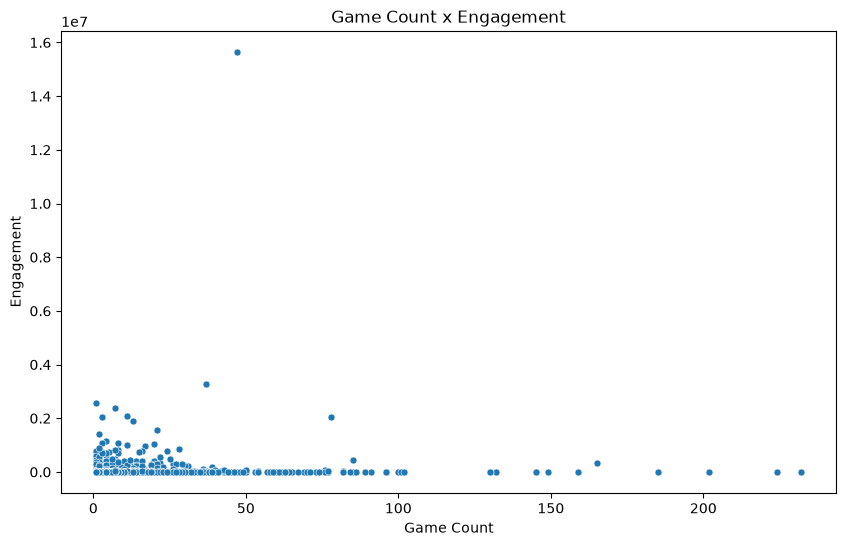

In [152]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='game_count',
    y='engagement',
    data=developers_df,
    s=25
)
plt.title('Game Count x Engagement')
plt.xlabel('Game Count')
plt.ylabel('Engagement')
plt.show()

It is clear that we have some data points heavily skewing our view, but at a first glance, we can see a bulk of the data with low engagement and low game count, but let's investigate further

Let us look at `game_count` across developers with a histogram, applying log scaling to our frequency axis

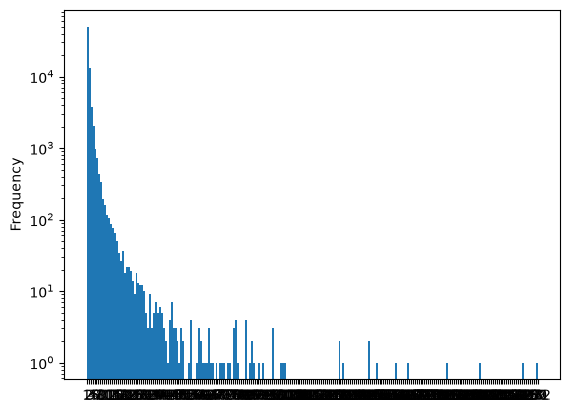

In [153]:
maxX = round(developers_df["game_count"].max())
developers_df["game_count"].plot.hist(bins=range(1,maxX+1))
plt.yscale("log")
plt.xticks(range(1,maxX+1));

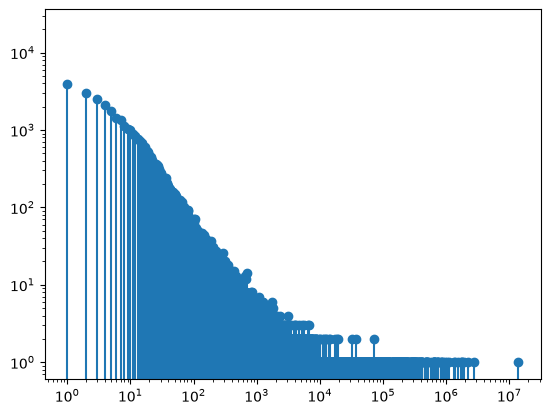

In [154]:
freq = developers_df['total_positive'].value_counts().sort_index()

plt.stem(freq.index, freq.values)
plt.yscale("log")
plt.xscale("log")

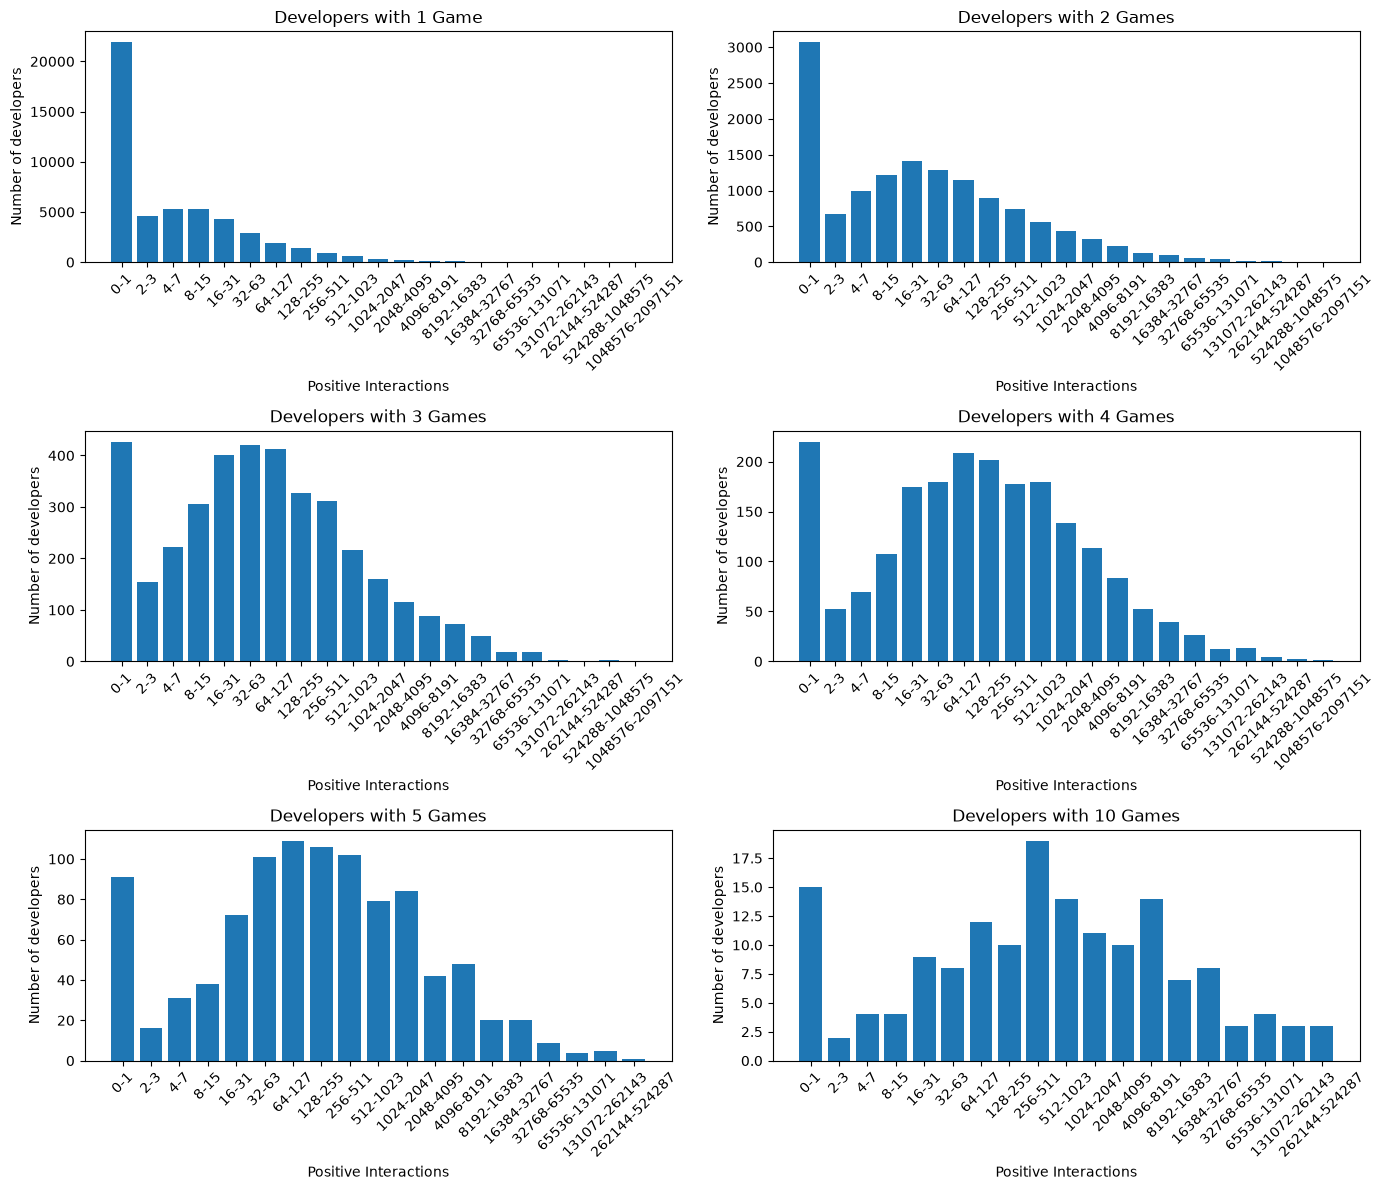

In [155]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

# 1 game count
dev_game_one = developers_df[developers_df["game_count"] == 1]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_one["total_positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_one["total_positive"], bins=bins)
axes[0].bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
axes[0].set_title("Developers with 1 Game")
axes[0].set_xlabel("Positive Interactions")
axes[0].set_ylabel("Number of developers")
axes[0].tick_params(axis='x', rotation=45)

# 2 game count
dev_game_two = developers_df[developers_df["game_count"] == 2]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_two["total_positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_two["total_positive"], bins=bins)
axes[1].bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
axes[1].set_title("Developers with 2 Games")
axes[1].set_xlabel("Positive Interactions")
axes[1].set_ylabel("Number of developers")
axes[1].tick_params(axis='x', rotation=45)

# 3 game count
dev_game_three = developers_df[developers_df["game_count"] == 3]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_three["total_positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_three["total_positive"], bins=bins)
axes[2].bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
axes[2].set_title("Developers with 3 Games")
axes[2].set_xlabel("Positive Interactions")
axes[2].set_ylabel("Number of developers")
axes[2].tick_params(axis='x', rotation=45)

# 4 game count
dev_game_four = developers_df[developers_df["game_count"] == 4]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_four["total_positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_four["total_positive"], bins=bins)
axes[3].bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
axes[3].set_title("Developers with 4 Games")
axes[3].set_xlabel("Positive Interactions")
axes[3].set_ylabel("Number of developers")
axes[3].tick_params(axis='x', rotation=45)

# 5 game count
dev_game_five = developers_df[developers_df["game_count"] == 5]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_five["total_positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_five["total_positive"], bins=bins)
axes[4].bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
axes[4].set_title("Developers with 5 Games")
axes[4].set_xlabel("Positive Interactions")
axes[4].set_ylabel("Number of developers")
axes[4].tick_params(axis='x', rotation=45)

# 10 game count
dev_game_ten = developers_df[developers_df["game_count"] == 10]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_ten["total_positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_ten["total_positive"], bins=bins)
axes[5].bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
axes[5].set_title("Developers with 10 Games")
axes[5].set_xlabel("Positive Interactions")
axes[5].set_ylabel("Number of developers")
axes[5].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Let's look how the mean and the median fluctuate according to incresing game counts

In [156]:
# quick dictionary to allow for iterating through our existing dataframes
dfs_dict = {
    1: dev_game_one,
    2: dev_game_two,
    3: dev_game_three,
    4: dev_game_four,
    5: dev_game_five,
    10: dev_game_ten
}

for count, df_subset in dfs_dict.items():
    mean = df_subset['total_positive'].mean()
    median = df_subset['total_positive'].median()
    print(f"Games: {count} | Median Positive Reviews: {median}")
    print(f"Games: {count} | Mean Positive Reviews: {mean}")
    print("--------------------------")

Games: 1 | Median Positive Reviews: 3.0
Games: 1 | Mean Positive Reviews: 296.0488634544581
--------------------------
Games: 2 | Median Positive Reviews: 23.0
Games: 2 | Mean Positive Reviews: 1893.4449513836948
--------------------------
Games: 3 | Median Positive Reviews: 56.0
Games: 3 | Mean Positive Reviews: 2644.587399463807
--------------------------
Games: 4 | Median Positive Reviews: 133.5
Games: 4 | Mean Positive Reviews: 5390.886673151751
--------------------------
Games: 5 | Median Positive Reviews: 159.0
Games: 5 | Mean Positive Reviews: 3635.5092024539877
--------------------------
Games: 10 | Median Positive Reviews: 463.0
Games: 10 | Mean Positive Reviews: 15331.14375
--------------------------


In [157]:
dev_game_one['total_positive'].median()

np.float64(3.0)

In [158]:
dev_game_two['total_positive'].median()

np.float64(23.0)

## Outliers

In [159]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,max_success,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04,72859.000000,72859,72859,72859.000000,7.285900e+04,7.285900e+04,72859.000000,72859.000000
mean,1.858755,1.758784e+03,2.848075e+02,4.857781,1.308611e+03,3.291000,2022-01-01 21:53:54.263440,2022-09-01 07:29:23.905626,11.409789,2.043591e+03,6.294165e+02,1.661483,1.184051
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,1997-06-30 00:00:00,2003-11-01 00:00:00,0.000000,0.000000e+00,0.000000e+00,1.000000,0.100000
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00,2.000000,2019-09-23 00:00:00,2020-09-30 00:00:00,7.606000,0.000000e+00,0.000000e+00,1.000000,1.000000
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,6.000000e+00,3.000000,2022-10-18 00:00:00,2023-08-14 00:00:00,9.887000,8.000000e+00,7.000000e+00,1.000000,1.000000
75%,2.000000,4.800000e+01,1.300000e+01,5.990000,4.100000e+01,4.000000,2024-10-24 00:00:00,2025-03-06 00:00:00,13.368000,6.400000e+01,4.058571e+01,1.000000,1.000000
max,232.000000,1.377616e+07,1.870072e+06,999.980000,7.642084e+06,20.000000,2026-12-01 00:00:00,2026-12-01 00:00:00,209.526000,1.564624e+07,2.557944e+06,27.000000,74.500000
std,3.712594,5.793022e+04,9.118371e+03,9.637942,3.448315e+04,1.574045,NaN,NaN,6.038973,6.621155e+04,1.314414e+04,1.853833,0.809167


/home/mango/BSU/fall26/dataMining/finalProject/.venv/lib64/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


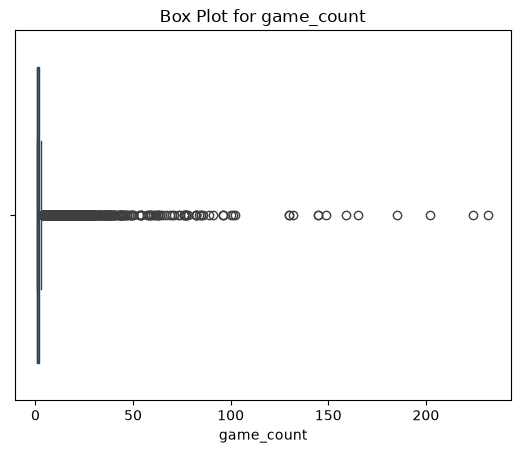

In [160]:
sns.boxplot(x=developers_df['game_count'])
plt.title("Box Plot for game_count")
plt.show()

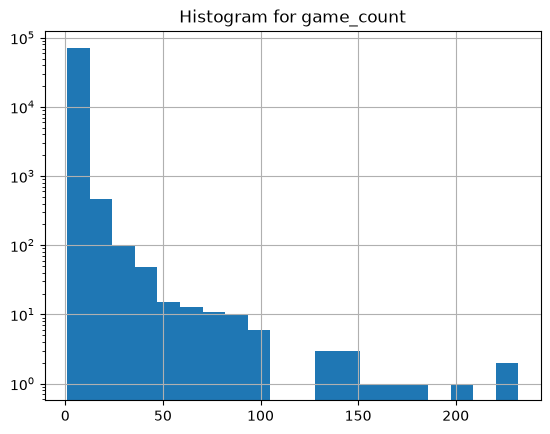

In [161]:
developers_df['game_count'].hist(bins=20, log=True)
plt.title("Histogram for game_count")
plt.show()

In [162]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,max_success,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04,72859.000000,72859,72859,72859.000000,7.285900e+04,7.285900e+04,72859.000000,72859.000000
mean,1.858755,1.758784e+03,2.848075e+02,4.857781,1.308611e+03,3.291000,2022-01-01 21:53:54.263440,2022-09-01 07:29:23.905626,11.409789,2.043591e+03,6.294165e+02,1.661483,1.184051
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,1997-06-30 00:00:00,2003-11-01 00:00:00,0.000000,0.000000e+00,0.000000e+00,1.000000,0.100000
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00,2.000000,2019-09-23 00:00:00,2020-09-30 00:00:00,7.606000,0.000000e+00,0.000000e+00,1.000000,1.000000
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,6.000000e+00,3.000000,2022-10-18 00:00:00,2023-08-14 00:00:00,9.887000,8.000000e+00,7.000000e+00,1.000000,1.000000
75%,2.000000,4.800000e+01,1.300000e+01,5.990000,4.100000e+01,4.000000,2024-10-24 00:00:00,2025-03-06 00:00:00,13.368000,6.400000e+01,4.058571e+01,1.000000,1.000000
max,232.000000,1.377616e+07,1.870072e+06,999.980000,7.642084e+06,20.000000,2026-12-01 00:00:00,2026-12-01 00:00:00,209.526000,1.564624e+07,2.557944e+06,27.000000,74.500000
std,3.712594,5.793022e+04,9.118371e+03,9.637942,3.448315e+04,1.574045,NaN,NaN,6.038973,6.621155e+04,1.314414e+04,1.853833,0.809167


In [163]:
z = np.abs(stats.zscore(developers_df['game_count']))
outliers_game_count = developers_df[z > 3]
outliers_game_count.shape

(684, 15)

In [164]:
outliers_game_count.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
53,07th Expansion,14,15272,604,8.019286,5114,"Action,Adventure,Casual,Indie",4,2015-05-15,2023-11-09,10.550000,15876,1134.000000,9,1.555556
86,"100 Cozy Games,Cats",82,33,1,0.891220,33,"Action,Adventure,Casual,Free To Play,Indie,RPG...",9,2023-12-17,2026-02-09,14.024683,34,0.414634,4,20.500000
116,10tons Ltd,22,9303,1051,4.210588,2778,"Action,Adventure,Casual,Indie,RPG,Simulation,S...",8,2014-06-11,2023-03-30,12.627529,10354,470.636364,10,2.200000
118,11 bit studios,14,231666,22877,6.131000,114315,"Action,Adventure,Free To Play,Indie,Simulation...",7,2011-04-08,2025-06-13,15.994600,254543,18181.642857,15,0.933333
164,16air,16,73,13,1.240769,20,"Action,Adventure,Casual,Indie,RPG,Simulation,S...",7,2018-09-04,2025-10-23,10.854923,86,5.375000,8,2.000000


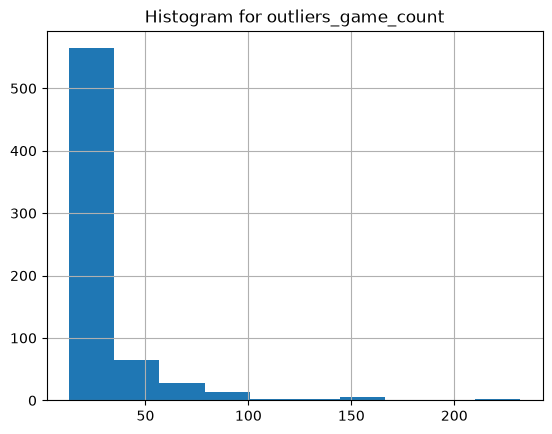

In [165]:
outliers_game_count['game_count'].hist(bins=10)
plt.title("Histogram for outliers_game_count")
plt.show()

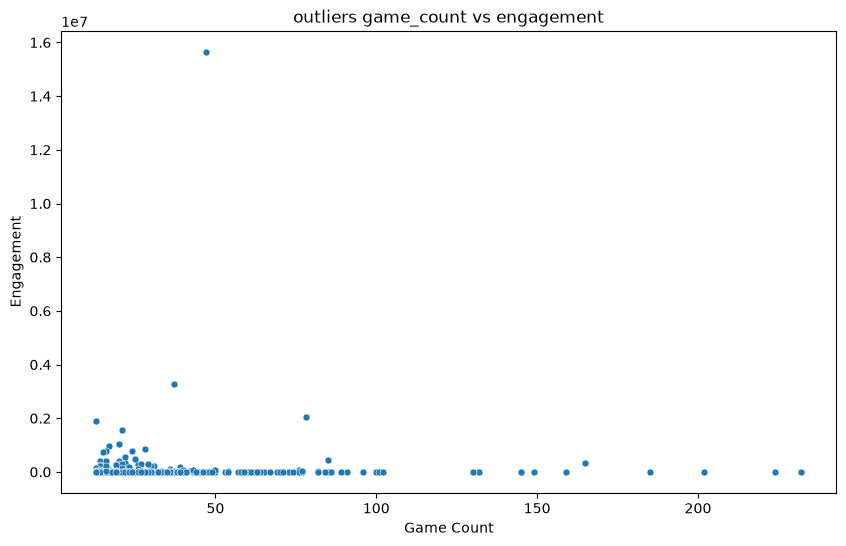

In [166]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=outliers_game_count,
    x='game_count',
    y='engagement',
    s=25
)
plt.title('outliers game_count vs engagement')
plt.xlabel('Game Count')
plt.ylabel('Engagement')
plt.show()

In [167]:
z = np.abs(stats.zscore(developers_df['engagement']))
outliers_engagement = developers_df[z > 3]
outliers_engagement.shape


(124, 15)

In [168]:
outliers_engagement.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
118,11 bit studios,14,231666,22877,6.131000,114315,"Action,Adventure,Free To Play,Indie,Simulation...",7,2011-04-08,2025-06-13,15.9946,254543,18181.642857,15,0.933333
301,24 Entertainment,2,225960,98967,0.000000,225960,"Action,Adventure,Free To Play,Massively Multip...",4,2021-08-11,2021-08-11,28.2080,324927,162463.500000,1,2.000000
456,"343 Industries,Splash Damage,Ruffian Games,Bun...",5,223635,18432,2.497500,223635,Action,1,2019-12-03,2022-09-06,5.2455,242067,48413.400000,4,1.250000
618,4A Games,6,274022,28356,3.240000,108945,Action,1,2014-08-25,2020-02-14,14.7360,302378,50396.333333,7,0.857143
1444,ATLUS,26,292378,18534,18.456667,99657,"Action,Adventure,RPG,Strategy",4,2019-01-10,2025-06-18,13.8504,310912,11958.153846,7,3.714286


In [169]:
Q1_game_count = developers_df['game_count'].quantile(0.25)
Q3_game_count = developers_df['game_count'].quantile(0.75)
IQR_game_count = Q3_game_count - Q1_game_count

lower_bound_game_count = Q1_game_count - 1.5 * IQR_game_count
upper_bound_game_count = Q3_game_count + 1.5 * IQR_game_count


outliers_game_count = developers_df[(developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count)]
outliers_game_count.shape

(5783, 15)

In [170]:
Q1_engagement = developers_df['engagement'].quantile(0.25)
Q3_engagement = developers_df['engagement'].quantile(0.75)
IQR_engagement = Q3_engagement - Q1_engagement

lower_bound_engagement = Q1_engagement - 1.5 * IQR_engagement
upper_bound_engagement = Q3_engagement + 1.5 * IQR_engagement

outliers_engagement = developers_df[(developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement)]
outliers_engagement

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
8,#workshop,6,9127,361,2.350000,3889,"Adventure,Casual,Indie",3,2019-02-27,2020-03-16,8.384667,9488,1581.333333,2,3.000000
18,"+Mpact Games, LLC.",2,172,56,0.000000,172,"Action,Adventure,Indie",3,2021-09-14,2021-09-14,20.620000,228,114.000000,1,2.000000
30,.GRAVITY,1,352,80,17.490000,352,"Adventure,Casual,Early Access,Indie,RPG,Simula...",6,2025-05-01,2025-05-01,24.776000,432,432.000000,1,1.000000
35,//commentout,2,440,49,7.190000,440,"Action,Indie",2,2022-06-01,2022-06-01,19.414000,489,244.500000,1,2.000000
38,0 Deer Soft,8,1150,250,2.976667,406,"Adventure,Casual,Free To Play,Indie",4,2021-09-17,2024-07-19,8.243000,1400,175.000000,4,2.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72745,鸽屋谷,1,242,0,2.990000,242,"Casual,Early Access,Indie,RPG,Simulation",5,2020-10-17,2020-10-17,9.872000,242,242.000000,1,1.000000
72747,鹊思网络,1,122,118,1.880000,122,"Casual,Indie,Simulation",3,2020-10-27,2020-10-27,10.850000,240,240.000000,1,1.000000
72756,黄昏フロンティア,3,2475,323,20.990000,1758,"Action,Casual,Indie",3,2018-01-05,2021-10-29,8.728667,2798,932.666667,4,0.750000
72835,유진게임즈,19,293,31,2.994615,187,"Casual,Free To Play,Indie,Simulation,Strategy",5,2020-09-03,2025-03-12,10.459077,324,17.052632,6,3.166667


In [171]:
outliers_either = developers_df[(developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement) | (developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count)]

outliers_either.shape

(14796, 15)

In [172]:
outliers_both = developers_df[((developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement)) & ((developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count))]

outliers_both.shape

(3547, 15)

## D. Exploratory Data Analysis

## E. Pattern Discovery

In [173]:
essential_attributes_df.shape

(117406, 15)

In [174]:
essential_attributes_df.columns

Index(['AppID', 'Name', 'Release date', 'Price', 'DLC count', 'About the game',
       'Positive', 'Negative', 'Recommendations', 'Developers', 'Genres',
       'Screenshots', 'Movies', 'Effort', 'game_weight'],
      dtype='str')

In [175]:
essential_attributes_df.columns

Index(['AppID', 'Name', 'Release date', 'Price', 'DLC count', 'About the game',
       'Positive', 'Negative', 'Recommendations', 'Developers', 'Genres',
       'Screenshots', 'Movies', 'Effort', 'game_weight'],
      dtype='str')

## K-Means on 2 features

To keep our data 2-dimensional, let us only first look at engagement (the sum of positive and negative reviews) and the game count

In [176]:
kmeans_df = developers_df[['game_count', 'engagement']].copy()
kmeans_df = kmeans_df.dropna() # dropping all missing entries for now, later we will revisit this

Scaling our features

In [177]:
scaler = StandardScaler()
kmeans_df_scaled = scaler.fit_transform(kmeans_df)

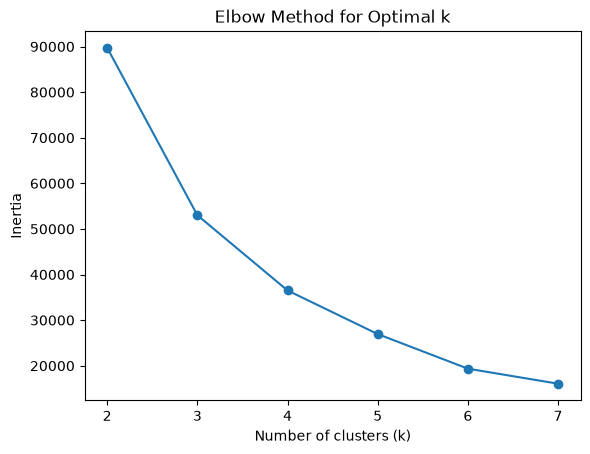

In [178]:
inertia = []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(kmeans_df_scaled)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

For now, let us go with K = 4

In [179]:
# initializing an instance of K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init='auto'
)

# fitting the model and predicting cluster labels for each row
clusters = kmeans.fit_predict(kmeans_df_scaled)

# adding the cluster labels back to our developers dataframe
developers_df.loc[kmeans_df.index, 'Cluster'] = clusters
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,0.0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,0.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,0.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,0.0


In [180]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,max_success,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04,72859.000000,72859,72859,72859.000000,7.285900e+04,7.285900e+04,72859.000000,72859.000000,72859.000000
mean,1.858755,1.758784e+03,2.848075e+02,4.857781,1.308611e+03,3.291000,2022-01-01 21:53:54.263440,2022-09-01 07:29:23.905626,11.409789,2.043591e+03,6.294165e+02,1.661483,1.184051,0.052979
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,1997-06-30 00:00:00,2003-11-01 00:00:00,0.000000,0.000000e+00,0.000000e+00,1.000000,0.100000,0.000000
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00,2.000000,2019-09-23 00:00:00,2020-09-30 00:00:00,7.606000,0.000000e+00,0.000000e+00,1.000000,1.000000,0.000000
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,6.000000e+00,3.000000,2022-10-18 00:00:00,2023-08-14 00:00:00,9.887000,8.000000e+00,7.000000e+00,1.000000,1.000000,0.000000
75%,2.000000,4.800000e+01,1.300000e+01,5.990000,4.100000e+01,4.000000,2024-10-24 00:00:00,2025-03-06 00:00:00,13.368000,6.400000e+01,4.058571e+01,1.000000,1.000000,0.000000
max,232.000000,1.377616e+07,1.870072e+06,999.980000,7.642084e+06,20.000000,2026-12-01 00:00:00,2026-12-01 00:00:00,209.526000,1.564624e+07,2.557944e+06,27.000000,74.500000,3.000000
std,3.712594,5.793022e+04,9.118371e+03,9.637942,3.448315e+04,1.574045,NaN,NaN,6.038973,6.621155e+04,1.314414e+04,1.853833,0.809167,0.393151


In [181]:
cluster_summary = developers_df.groupby('Cluster')[['game_count','engagement']].mean()
print(cluster_summary)

         game_count    engagement
Cluster                          
0.0        1.548419  9.218784e+02
1.0       47.000000  1.564624e+07
2.0       95.089286  5.444214e+04
3.0       15.421137  5.142984e+04


In [182]:
print(developers_df['Cluster'].value_counts())

Cluster
0.0    71553
3.0     1249
2.0       56
1.0        1
Name: count, dtype: int64


In [183]:
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,0.0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,0.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,0.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,0.0


## Testing K-Means with all features

In [184]:
developers_df.columns

Index(['Developers', 'game_count', 'total_positive', 'total_negative',
       'avg_price', 'max_success', 'genres', 'genre_count', 'start_year',
       'end_year', 'avg_effort', 'engagement', 'avg_game_success',
       'years_active', 'frequency', 'Cluster'],
      dtype='str')

In [185]:
scaler = StandardScaler()

kmeans_df = developers_df[['game_count', 'total_positive', 'total_negative', 'avg_price', 'max_success', 'genre_count', 'avg_game_success', 'years_active','frequency']].copy()

kmeans_df_scaled_all_features = scaler.fit_transform(kmeans_df)
# kmeans_df.head()

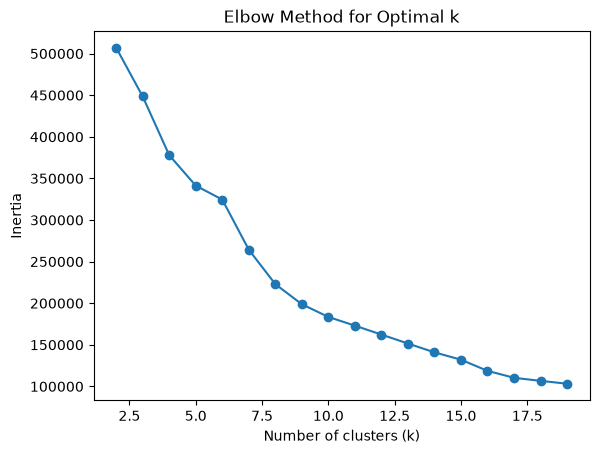

In [186]:
inertia = []
K_range = range(2, 20)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(kmeans_df_scaled_all_features)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

In [187]:
# initializing an instance of K-Means
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init='auto'
)

# fitting the model and predicting cluster labels for each row
clusters = kmeans.fit_predict(kmeans_df_scaled_all_features)

# adding the cluster labels back to our developers dataframe
developers_df.loc[kmeans_df.index, 'Cluster'] = clusters
developers_df.head()


,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,3.0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,4.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,4.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,4.0


In [188]:
cluster_summary = developers_df.groupby('Cluster')[['game_count', 'total_positive', 'total_negative', 'avg_price', 'max_success', 'genre_count', 'avg_game_success', 'years_active','frequency']].mean()
print(cluster_summary)

         game_count  total_positive  total_negative  avg_price   max_success  \
Cluster                                                                        
0.0        1.474151    3.097376e+02    6.864783e+01   4.278191  2.920465e+02   
1.0       47.000000    1.377616e+07    1.870072e+06   1.508571  7.642084e+06   
2.0       67.728972    5.275187e+04    1.079128e+04   8.778071  1.731554e+04   
3.0        5.959331    1.476961e+04    2.293634e+03   5.446917  1.065182e+04   
4.0        1.102584    2.054412e+02    3.728375e+01   4.367378  1.954930e+02   
5.0        2.725660    2.011803e+03    3.344102e+02   7.788321  1.907348e+03   

         genre_count  avg_game_success  years_active  frequency  
Cluster                                                          
0.0         4.807407        230.628927      1.394340   1.078274  
1.0         7.000000     332898.617021     25.000000   1.880000  
2.0         6.616822       1370.935251      6.392523  13.020892  
3.0         4.829733       43

In [189]:
print(developers_df['Cluster'].value_counts())

Cluster
4.0    36955
0.0    21413
5.0     9244
3.0     5139
2.0      107
1.0        1
Name: count, dtype: int64


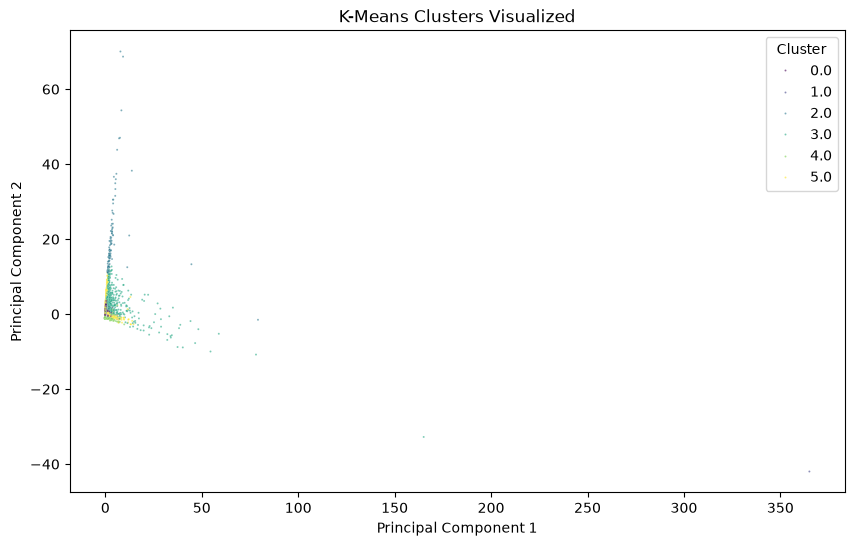

In [190]:
# reducing the scaled features to 2 dimensions
pca = PCA(n_components=2)
components = pca.fit_transform(kmeans_df_scaled_all_features)

# creating a temporary dataframe for plotting
plot_df = pd.DataFrame(components, columns=['PC1', 'PC2'])
plot_df['Cluster'] = developers_df.loc[kmeans_df.index, 'Cluster'].values

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    data=plot_df, 
    palette='viridis', 
    alpha=0.6,
    s=2
)
plt.title('K-Means Clusters Visualized')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

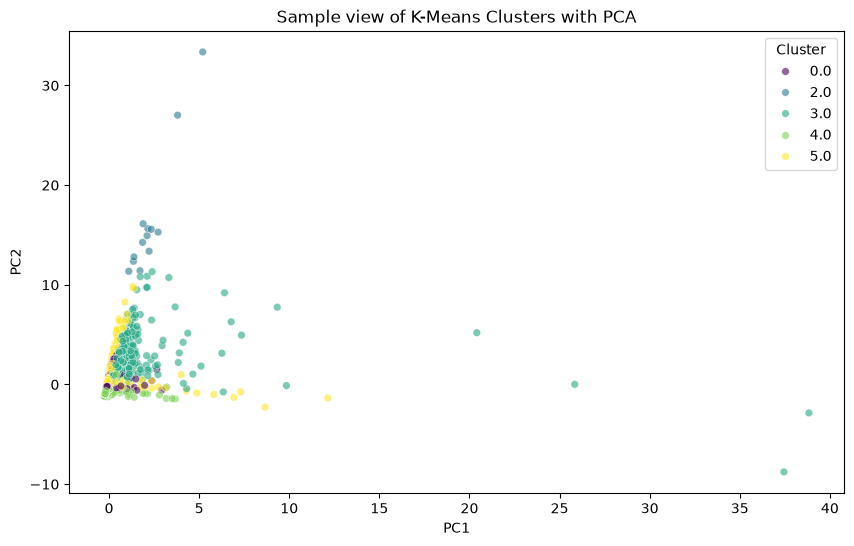

In [191]:
# sampling 10.000 developers
plot_sample = plot_df.sample(n=10000, random_state=52)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    data=plot_sample, 
    palette='viridis', 
    alpha=0.6,
    s=30
)
plt.title('Sample view of K-Means Clusters with PCA')
plt.show()

In [192]:
regulars = developers_df[developers_df['Cluster'] != 2.0]
regulars = regulars[regulars['Cluster'] != 1.0]
print(regulars['Cluster'].value_counts())

Cluster
4.0    36955
0.0    21413
5.0     9244
3.0     5139
Name: count, dtype: int64


## K-Means with game_count, max_success, avg_effort,

In [193]:
developers_df['game_count'] = developers_df['game_count'].clip(upper=10)
developers_df['avg_price'] = developers_df['avg_price'].clip(upper=100)

In [194]:
scaler = StandardScaler()

regulars_kmeans = regulars[['game_count', 'max_success', 'avg_effort']].copy()

kmeans_regulars_df_scaled_all_features = scaler.fit_transform(regulars_kmeans)

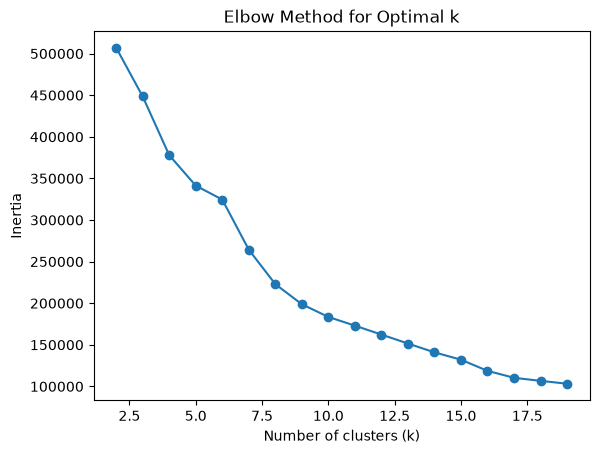

In [195]:
inertia = []
K_range = range(2, 20)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(kmeans_df_scaled_all_features)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

In [196]:
# initializing an instance of K-Means
kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init='auto'
)

# fitting the model and predicting cluster labels for each row
clusters = kmeans.fit_predict(kmeans_regulars_df_scaled_all_features)

# adding the cluster labels back to our developers dataframe
developers_df.loc[regulars_kmeans.index, 'Cluster'] = clusters
developers_df.head()


,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,4.0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,5.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,5.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,0.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,0.0


In [197]:
developers_df['Cluster'].value_counts()

Cluster
5.0    44759
0.0    17690
4.0     6592
3.0     2158
6.0     1220
2.0      341
7.0       81
1.0       18
Name: count, dtype: int64

In [198]:
cluster_summary = developers_df.groupby('Cluster')[['game_count', 'total_positive', 'total_negative', 'max_success', 'avg_effort', 'avg_game_success', 'years_active','frequency']].mean()
print(cluster_summary)

         game_count  total_positive  total_negative   max_success  avg_effort  \
Cluster                                                                         
0.0        1.365065    8.497920e+02      149.194686  8.204105e+02   16.234034   
1.0        5.500000    1.859367e+06   268259.500000  1.319826e+06   17.095387   
2.0       10.000000    3.062811e+04     6347.759531  1.064332e+04   10.848209   
3.0        1.622799    1.849144e+03      439.843373  1.607423e+03   33.596083   
4.0        4.127124    2.612196e+03      439.244842  2.008869e+03   11.033670   
5.0        1.192542    1.831371e+02       31.105253  1.789793e+02    8.465934   
6.0        9.312295    9.319136e+03     1583.964754  4.643301e+03   11.930907   
7.0        4.358025    3.508790e+05    48752.037037  2.846639e+05   17.309825   

         avg_game_success  years_active  frequency  
Cluster                                             
0.0            608.026274      1.359016   1.167888  
1.0         470009.961765     

In [199]:
developers_df['Cluster'].value_counts()

Cluster
5.0    44759
0.0    17690
4.0     6592
3.0     2158
6.0     1220
2.0      341
7.0       81
1.0       18
Name: count, dtype: int64

## A priori

### Adding a succesful tag to each developer 

In [200]:
developers_df['succesful'] = 0
developers_df.loc[developers_df['avg_game_success'] >=1000, 'succesful'] = 1

In [201]:
#-- Dependencies -----------------------------------
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

developers_df.head()

devTags = []
for row in developers_df.itertuples(index=False):
    tags = []
    if(row.succesful): tags.append('successful')
    for genre in row.genres.split(','): tags.append('Genre: '+genre)
    tags.append(str(row.start_year.year))
    if row.avg_effort > 15: tags.append("high effort")
    # if row.frequency > 1.5: tags.append('frequent')
    if row.game_count == 1: tags.append('Game Count: 1')
    elif row.game_count == 2: tags.append('Game Count: 2')
    elif row.game_count == 3: tags.append('Game Count: 3')
    elif row.game_count == 4: tags.append('Game Count: 4')
    elif row.game_count == 5: tags.append('Game Count: 5')
    elif row.game_count < 10: tags.append('Game Count: 6-9')
    else: tags.append('Game Count: 10+')
    devTags.append(tags)


In [202]:
te = TransactionEncoder()
te_array = te.fit(devTags).transform(devTags)
dev_encoded = pd.DataFrame(
    te_array,
    columns=te.columns_
)
dev_encoded.head()
frequent_itemsets = apriori(
    dev_encoded,
    min_support=0.01, # Only about 5.78% of developers are successful, we are selecting from within this subset
    use_colnames=True,
)

In [203]:
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.0733 # tuned for 20 results
)
successful_rules = rules[
    rules['consequents'].apply(
        lambda x: 'successful' in x
    )
].sort_values(
    by='lift',
    ascending=False
)
len(successful_rules)
successful_rules.head(20)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
2091,"frozenset({high effort, Genre: Action})",frozenset({successful}),0.095568,0.045567,0.011378,0.119058,2.612782,1.0,0.007023,1.083423,0.682491,0.087688,0.076999,0.184378
375,frozenset({high effort}),frozenset({successful}),0.176629,0.045567,0.018405,0.104204,2.286805,1.0,0.010357,1.065457,0.683420,0.090315,0.061436,0.254060
2531,"frozenset({high effort, Genre: Indie})",frozenset({successful}),0.137251,0.045567,0.012545,0.091400,2.005817,1.0,0.006291,1.050443,0.581224,0.073674,0.048021,0.183351
233,frozenset({Game Count: 2}),frozenset({successful}),0.183505,0.045567,0.014206,0.077412,1.698846,1.0,0.005844,1.034517,0.503818,0.066113,0.033365,0.194580
2238,"frozenset({Genre: Adventure, Genre: RPG})",frozenset({successful}),0.136057,0.045567,0.010115,0.074347,1.631577,1.0,0.003916,1.031091,0.448057,0.058979,0.030153,0.148167


I removed the "frequent" tag because it dominated the results. In other words, being a frequent developer strongly suggested success. To understand why I thought this wasn't an interesting result, consider that (frequent+2 games)->(success). This suggested, to me, that a successful developer will quickly produce a second game.

## Regression

game count vs avg_game_success

In [204]:
input_array = np.array(developers_df['game_count']).reshape((-1, 1))
output_array = np.array(developers_df['avg_game_success'])

model = LinearRegression()

model.fit(input_array, output_array)

r_sq = model.score(input_array, output_array)
print(f"coefficient of determination: {r_sq}")

print(f"intercept: {model.intercept_}")
print(f"slope: {model.coef_}")

coefficient of determination: 0.0008624582489840105
intercept: 208.58552984161128
slope: [248.35833466]


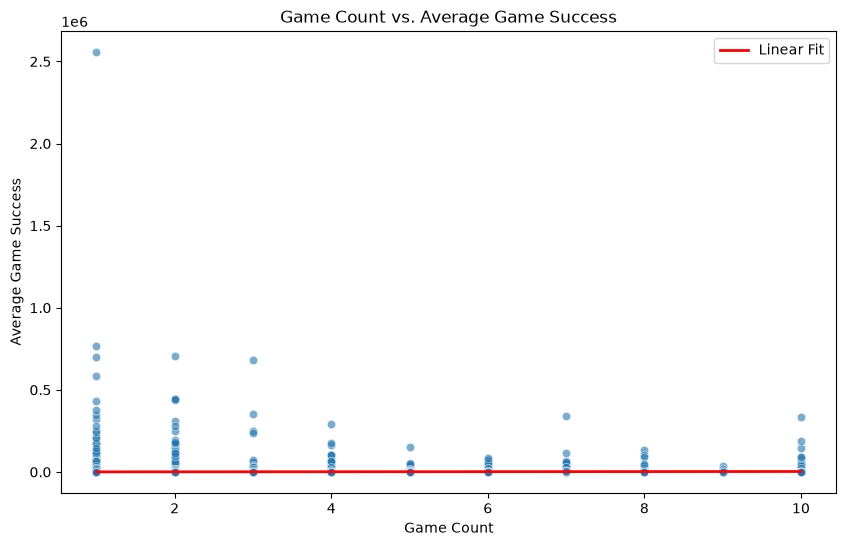

In [205]:
# plotting the line onto a scatterplot of those same features

X = developers_df[['game_count']]
y = developers_df['avg_game_success']


# generatting an evenly spaced sequence for the line
x_range = np.linspace(X['game_count'].min(), X['game_count'].max(), 100).reshape(-1, 1)

# predicting on the given range
y_pred = model.predict(x_range)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=developers_df, 
    x='game_count', 
    y='avg_game_success', 
    alpha=0.6
)
plt.plot(
    x_range, 
    y_pred, 
    color='red', 
    linewidth=2, 
    label='Linear Fit'
)

plt.title('Game Count vs. Average Game Success')
plt.xlabel('Game Count')
plt.ylabel('Average Game Success')
plt.legend()
plt.show()

## Multiple linear regression

Input: game_count and avg_game_price
Output: avg_game_success

In [206]:
input_array = developers_df[['game_count', 'avg_price']]
input_array = input_array.values

output_array = np.array(developers_df['avg_game_success'])

model = LinearRegression()

model.fit(input_array, output_array)

r_sq = model.score(input_array, output_array)
print(f"coefficient of determination: {r_sq}")

print(f"intercept: {model.intercept_}")
print(f"slope: {model.coef_}")

coefficient of determination: 0.001280023408739006
intercept: 20.54958068328358
slope: [242.77039512  41.5290564 ]


## F. Evaluation

## G. Decision Sensitivity Analysis

## H. Interpretation